# Objetivo 3 — Transformer (RoBERTa clínico en español) con ajuste fino LoRA
Correr en Google Colab con GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU (T4).
Antes de empezar, sube a Colab (ícono de carpeta, a la izquierda):
  - Audit HC (2).xlsx                                   (etiquetas del experto)
  - criterios_auditoria_fewshot_por_criterio.csv        (etiquetas del LLM)

## Diagnostico


In [2]:
# CELDA 1 — Instalar librerías (solo la primera vez en cada sesión de Colab)
!pip uninstall -y torchao
!pip install -q transformers peft accelerate

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [29]:
# CELDA 2 — Configuración (cambia SOLO esto para cada criterio)
import os, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback)
from peft import LoraConfig, get_peft_model, TaskType

RUTA_EXPERTO = "Audit HC (2).xlsx"
RUTA_LLM     = "criterios_auditoria_fewshot_por_criterio.csv"

#   Criterio            COL_EXP (experto)       COL_LLM (CSV del LLM)
#   Diagnóstico         "Diagnóstico"           "diagnostico"
#   Examen físico       "Examen Físico"         "examen_fisico"
#   Motivo de consulta  "Motivo de consulta"    "motivo_consulta"
COL_EXP = "Motivo de consulta"
COL_LLM = "motivo_consulta"
NOMBRE  = "Examen físico"            # sufijo para los archivos que se guardan

MODELO   = "PlanTL-GOB-ES/roberta-base-biomedical-clinical-es"
MAX_LEN  = 512                     # límite de RoBERTa
SEMILLAS = [42]                    # para la tesis, idealmente [42, 43, 44]

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DISPOSITIVO)


Dispositivo: cuda


In [30]:
# CELDA 3 — Datos: misma división que en los notebooks de los modelos clásicos
df_experto = pd.read_excel(RUTA_EXPERTO, sheet_name="Sheet1")
df_experto["caso"] = df_experto["caso"].astype(str)
df_exp = df_experto[df_experto[COL_EXP].notna()]

df_val, df_test = train_test_split(df_exp, test_size=0.5,
                                   stratify=df_exp[COL_EXP], random_state=42)

df_todas = pd.read_excel(RUTA_EXPERTO)                 # las 997 notas
df_todas["caso"] = df_todas["caso"].astype(str)
df_llm = pd.read_csv(RUTA_LLM)
df_llm["caso"] = df_llm["caso"].astype(str)
df_train = (df_todas[["caso", "nota"]]
            .merge(df_llm[["caso", COL_LLM]], on="caso", how="left"))
df_train = df_train[~df_train["caso"].isin(df_exp["caso"])].dropna(subset=[COL_LLM])

# El transformer usa la NOTA ORIGINAL: tiene su propio tokenizador
X_train, y_train = df_train["nota"].fillna("").tolist(), df_train[COL_LLM].astype(int).to_numpy()
X_val,   y_val   = df_val["nota"].fillna("").tolist(),   df_val[COL_EXP].astype(int).to_numpy()
X_test,  y_test  = df_test["nota"].fillna("").tolist(),  df_test[COL_EXP].astype(int).to_numpy()

print(f"Train (LLM): {len(y_train)} | No cumple: {(y_train == 0).sum()}")
print(f"Validación (experto): {len(y_val)} | No cumple: {(y_val == 0).sum()}")
print(f"Test (experto): {len(y_test)} | No cumple: {(y_test == 0).sum()}")

# 15 % de las notas del LLM para early stopping (la validación del experto NO se usa aquí)
X_fit, X_es, y_fit, y_es = train_test_split(X_train, y_train, test_size=0.15,
                                            stratify=y_train, random_state=42)


Train (LLM): 899 | No cumple: 178
Validación (experto): 49 | No cumple: 9
Test (experto): 49 | No cumple: 9


In [31]:
# CELDA 4 — Tokenizador y cuántas notas se cortan en 512 tokens
tokenizador = AutoTokenizer.from_pretrained(MODELO)
largos = [len(tokenizador(t)["input_ids"]) for t in X_train]
print(f"Subtokens por nota: mediana {np.median(largos):.0f} | máximo {max(largos)}")
print(f"Notas que superan {MAX_LEN} tokens (se cortan): {np.mean(np.array(largos) > MAX_LEN):.1%}")

class NotasDataset(Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizador(textos, truncation=True, max_length=MAX_LEN)
        self.etiquetas = etiquetas
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.etiquetas[i])
        return item

ds_fit, ds_es = NotasDataset(X_fit, y_fit), NotasDataset(X_es, y_es)
ds_val, ds_test = NotasDataset(X_val, y_val), NotasDataset(X_test, y_test)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (516 > 512). Running this sequence through the model will result in indexing errors


Subtokens por nota: mediana 423 | máximo 1509
Notas que superan 512 tokens (se cortan): 32.5%


In [32]:
# CELDA 5 — Modelo con LoRA y pérdida ponderada por clase
pesos_clase = torch.tensor(len(y_fit) / (2 * np.bincount(y_fit, minlength=2)), dtype=torch.float)
print("Pesos por clase (No cumple, Cumple):", pesos_clase.numpy().round(2))

def crear_modelo():
    base = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=2)
    config_lora = LoraConfig(
        task_type=TaskType.SEQ_CLS,        # clasificación de secuencias (entrena también la capa final)
        r=8,                               # rango de las matrices LoRA
        lora_alpha=16,                     # escala de la actualización LoRA
        lora_dropout=0.1,
        target_modules=["query", "value"], # matrices de atención que se adaptan
    )
    modelo = get_peft_model(base, config_lora)
    modelo.print_trainable_parameters()
    return modelo

class TrainerPonderado(Trainer):
    """Trainer con pérdida ponderada: los errores en 'No cumple' pesan más."""
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        etiquetas = inputs.pop("labels")
        salidas = model(**inputs)
        perdida = torch.nn.functional.cross_entropy(
            salidas.logits, etiquetas, weight=pesos_clase.to(salidas.logits.device))
        return (perdida, salidas) if return_outputs else perdida


Pesos por clase (No cumple, Cumple): [2.53 0.62]


In [33]:
# CELDA 6 — Entrenamiento (una corrida por semilla) y evaluación contra el experto
def metricas(y, pred):
    return {"F1 macro":      f1_score(y, pred, average="macro"),
            "Sensibilidad":  recall_score(y, pred, pos_label=1),   # recall "Cumple"
            "Especificidad": recall_score(y, pred, pos_label=0),   # recall "No cumple"
            "Exactitud":     accuracy_score(y, pred)}

def predecir(trainer, ds):
    logits = trainer.predict(ds).predictions
    prob = torch.softmax(torch.tensor(logits), dim=1)[:, 1].numpy()   # prob. de "Cumple"
    return (prob >= 0.5).astype(int), prob

filas, historiales, preds_test = [], [], []
for semilla in SEMILLAS:
    random.seed(semilla); np.random.seed(semilla); torch.manual_seed(semilla)
    modelo = crear_modelo()
    args = TrainingArguments(
        output_dir=f"lora_{NOMBRE}_{semilla}",
        num_train_epochs=10,
        learning_rate=2e-4,                    # LoRA usa tasas más altas que el fine-tuning completo
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,           # vuelve a la mejor época
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=1,
        logging_strategy="epoch",
        fp16=torch.cuda.is_available(),
        seed=semilla,
        report_to="none",
    )
    trainer = TrainerPonderado(
        model=modelo, args=args,
        train_dataset=ds_fit, eval_dataset=ds_es,
        data_collator=DataCollatorWithPadding(tokenizador),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    t0 = time.time()
    trainer.train()
    segundos = time.time() - t0

    for nombre, ds, y in [("Validación", ds_val, y_val), ("Test", ds_test, y_test)]:
        pred, _ = predecir(trainer, ds)
        filas.append({"Semilla": semilla, "Conjunto": nombre, **metricas(y, pred),
                      "Tiempo (s)": segundos})
        if nombre == "Test":
            preds_test.append(pred)
    historiales.append(trainer.state.log_history)
    print(f"✓ semilla {semilla}: {segundos:.0f} s")

res_lora = pd.DataFrame(filas)
display(res_lora.groupby("Conjunto")[["F1 macro", "Sensibilidad", "Especificidad", "Exactitud", "Tiempo (s)"]]
        .agg(["mean", "std"]).round(3))
res_lora.to_csv(f"resultados_lora_{NOMBRE}.csv", index=False)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 126,866,692 || trainable%: 0.6992


Epoch,Training Loss,Validation Loss
1,0.625604,0.585834
2,0.515793,0.458049
3,0.423380,0.458595
4,0.365581,0.460729


✓ semilla 42: 80 s


F1 macro     Sensibilidad     Especificidad     Exactitud      \
               mean std         mean std          mean std      mean std   
Conjunto                                                                   
Test          0.631 NaN        0.775 NaN         0.556 NaN     0.735 NaN   
Validación    0.812 NaN        0.825 NaN         1.000 NaN     0.857 NaN   

           Tiempo (s)      
                 mean std  
Conjunto                   
Test           80.457 NaN  
Validación     80.457 NaN

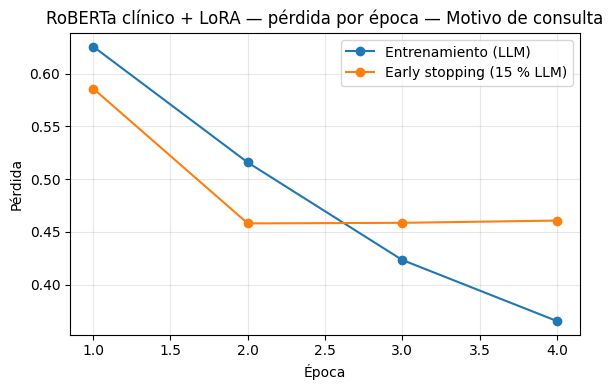

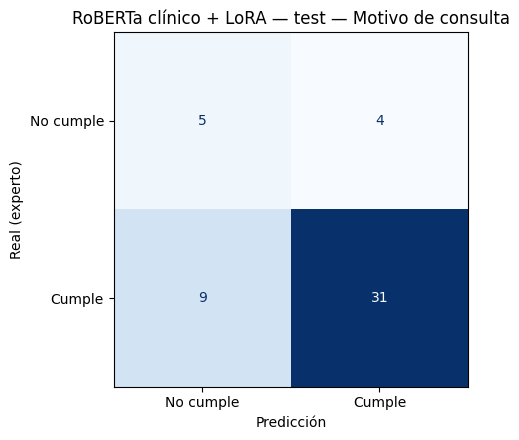

In [34]:
# CELDA 7 — Curva de pérdida por época y matriz de confusión (primera semilla)
log = pd.DataFrame(historiales[0])
ent = log.dropna(subset=["loss"])[["epoch", "loss"]]
ev  = log.dropna(subset=["eval_loss"])[["epoch", "eval_loss"]]
plt.figure(figsize=(6, 4))
plt.plot(ent["epoch"], ent["loss"], "o-", label="Entrenamiento (LLM)")
plt.plot(ev["epoch"], ev["eval_loss"], "o-", label="Early stopping (15 % LLM)")
plt.xlabel("Época"); plt.ylabel("Pérdida")
plt.title(f"RoBERTa clínico + LoRA — pérdida por época — {COL_EXP}")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"curva_perdida_lora_{NOMBRE}.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds_test[0], labels=[0, 1]),
                       display_labels=["No cumple", "Cumple"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title=f"RoBERTa clínico + LoRA — test — {COL_EXP}",
       xlabel="Predicción", ylabel="Real (experto)")
plt.tight_layout(); plt.savefig(f"matriz_confusion_lora_{NOMBRE}.png", dpi=200, bbox_inches="tight")
plt.show()


In [35]:
# CELDA 8 — Experimento 4b: Warm-up (solo cabeza) + Fine-tuning con LoRA
# Requiere haber corrido las celdas 1 a 7 (usa ds_fit, ds_es, ds_val, ds_test, crear_modelo, etc.)

def f1_en(trainer, ds, y):
    pred, _ = predecir(trainer, ds)
    return metricas(y, pred), pred

def argumentos(nombre, epocas, lr, mejor_al_final):
    return TrainingArguments(
        output_dir=f"lora_{NOMBRE}_{nombre}",
        num_train_epochs=epocas, learning_rate=lr,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        weight_decay=0.01,
        eval_strategy="epoch", save_strategy="epoch" if mejor_al_final else "no",
        load_best_model_at_end=mejor_al_final,
        metric_for_best_model="eval_loss", greater_is_better=False,
        save_total_limit=1, logging_strategy="epoch",
        fp16=torch.cuda.is_available(), seed=SEMILLAS[0], report_to="none",
    )

# --- 4a: resultados del LoRA directo (modelo entrenado en la celda 6) ---
trainer_4a = trainer
res_4a = {c: f1_en(trainer_4a, ds, y)[0] for c, ds, y in
          [("Train", ds_fit, y_fit), ("Validación", ds_val, y_val), ("Test", ds_test, y_test)]}
log_4a = pd.DataFrame(trainer_4a.state.log_history)

# --- 4b: FASE 1 — WARM-UP: todo congelado salvo la capa de clasificación ---
random.seed(SEMILLAS[0]); np.random.seed(SEMILLAS[0]); torch.manual_seed(SEMILLAS[0])
modelo_4b = crear_modelo()
for nombre_p, p in modelo_4b.named_parameters():
    p.requires_grad = "modules_to_save" in nombre_p          # solo la cabeza (classifier)
n_fase1 = sum(p.numel() for p in modelo_4b.parameters() if p.requires_grad)
print(f"FASE 1 (warm-up) — parámetros entrenables: {n_fase1:,}")

t0 = time.time()
trainer_f1 = TrainerPonderado(
    model=modelo_4b, args=argumentos("warmup", epocas=3, lr=1e-3, mejor_al_final=False),
    train_dataset=ds_fit, eval_dataset=ds_es,
    data_collator=DataCollatorWithPadding(tokenizador))
trainer_f1.train()
log_f1 = pd.DataFrame(trainer_f1.state.log_history)

# --- 4b: FASE 2 — FINE-TUNING: se activan también las matrices LoRA, con LR menor ---
for nombre_p, p in modelo_4b.named_parameters():
    p.requires_grad = ("lora_" in nombre_p) or ("modules_to_save" in nombre_p)
n_fase2 = sum(p.numel() for p in modelo_4b.parameters() if p.requires_grad)
print(f"FASE 2 (fine-tuning LoRA) — parámetros entrenables: {n_fase2:,}")

trainer_4b = TrainerPonderado(
    model=modelo_4b, args=argumentos("finetune", epocas=10, lr=1e-4, mejor_al_final=True),
    train_dataset=ds_fit, eval_dataset=ds_es,
    data_collator=DataCollatorWithPadding(tokenizador),
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
trainer_4b.train()
t_4b = time.time() - t0
log_f2 = pd.DataFrame(trainer_4b.state.log_history)

res_4b = {c: f1_en(trainer_4b, ds, y)[0] for c, ds, y in
          [("Train", ds_fit, y_fit), ("Validación", ds_val, y_val), ("Test", ds_test, y_test)]}
print(f"✓ Warm-up + fine-tuning: {t_4b:.0f} s")

# --- Tabla comparativa ---
filas = []
for modelo_n, res in [("4a: LoRA directo", res_4a), ("4b: Warm-up + LoRA", res_4b)]:
    for conj, m in res.items():
        filas.append({"Modelo": modelo_n, "Conjunto": conj, **m})
comparacion = pd.DataFrame(filas)
display(comparacion.pivot(index="Modelo", columns="Conjunto",
                          values=["F1 macro", "Especificidad", "Sensibilidad"]).round(3))
comparacion.to_csv(f"comparacion_4a_4b_{NOMBRE}.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 126,866,692 || trainable%: 0.6992
FASE 1 (warm-up) — parámetros entrenables: 592,130


Epoch,Training Loss,Validation Loss
1,0.671815,0.559732
2,0.526899,0.492305
3,0.455088,0.483608


FASE 2 (fine-tuning LoRA) — parámetros entrenables: 887,042


Epoch,Training Loss,Validation Loss
1,0.365594,0.497927
2,0.377164,0.472753
3,0.409303,0.484203
4,0.415245,0.489826


✓ Warm-up + fine-tuning: 111 s


F1 macro                   Especificidad                    \
Conjunto               Test  Train Validación          Test  Train Validación   
Modelo                                                                          
4a: LoRA directo      0.631  0.750      0.812         0.556  0.815        1.0   
4b: Warm-up + LoRA    0.590  0.784      0.834         0.444  0.854        1.0   

                   Sensibilidad                    
Conjunto                   Test  Train Validación  
Modelo                                             
4a: LoRA directo          0.775  0.808      0.825  
4b: Warm-up + LoRA        0.775  0.834      0.850

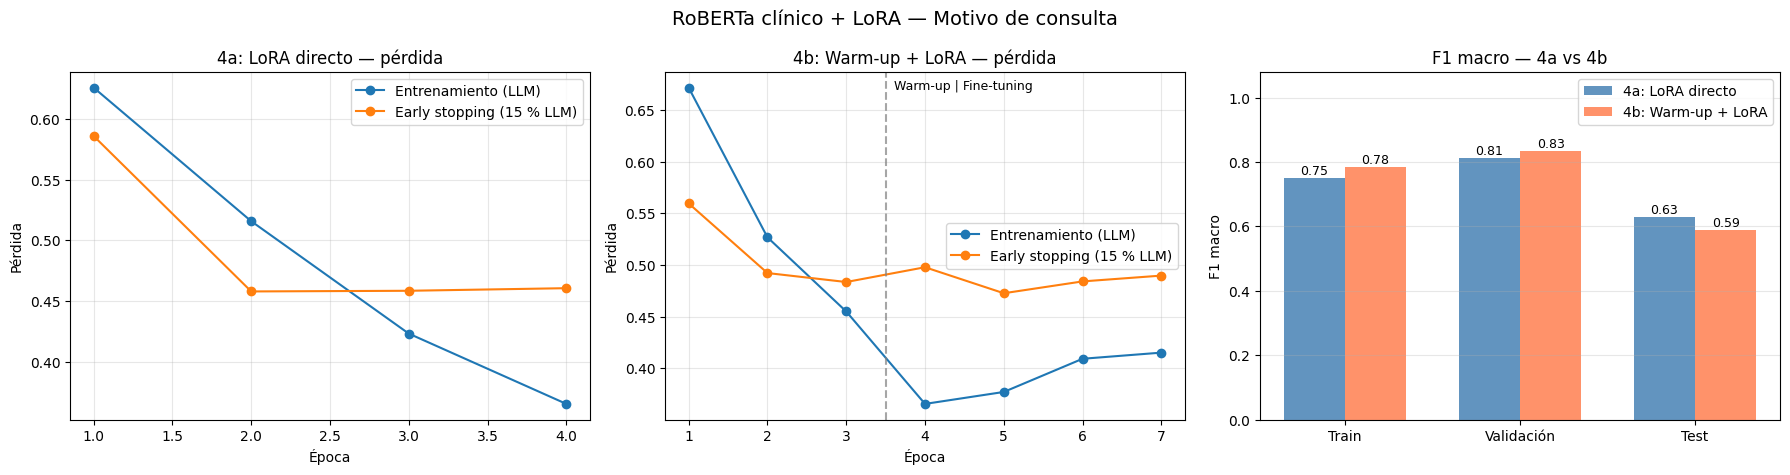

In [36]:
# CELDA 9 — Gráficas de comparación 4a vs 4b
def curvas(log):
    ent = log.dropna(subset=["loss"])[["epoch", "loss"]].reset_index(drop=True)
    ev  = log.dropna(subset=["eval_loss"])[["epoch", "eval_loss"]].reset_index(drop=True)
    return ent, ev

ent_a, ev_a = curvas(log_4a)
ent_1, ev_1 = curvas(log_f1)
ent_2, ev_2 = curvas(log_f2)
desfase = ent_1["epoch"].max()                       # las épocas de la fase 2 van después de la fase 1
ent_b = pd.concat([ent_1, ent_2.assign(epoch=ent_2["epoch"] + desfase)])
ev_b  = pd.concat([ev_1,  ev_2.assign(epoch=ev_2["epoch"] + desfase)])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (1) Curvas de pérdida 4a
axes[0].plot(ent_a["epoch"], ent_a["loss"], "o-", label="Entrenamiento (LLM)")
axes[0].plot(ev_a["epoch"], ev_a["eval_loss"], "o-", label="Early stopping (15 % LLM)")
axes[0].set(title="4a: LoRA directo — pérdida", xlabel="Época", ylabel="Pérdida")
axes[0].legend(); axes[0].grid(alpha=0.3)

# (2) Curvas de pérdida 4b, con la línea que separa las dos fases
axes[1].plot(ent_b["epoch"], ent_b["loss"], "o-", label="Entrenamiento (LLM)")
axes[1].plot(ev_b["epoch"], ev_b["eval_loss"], "o-", label="Early stopping (15 % LLM)")
axes[1].axvline(desfase + 0.5, color="gray", ls="--", alpha=0.7)
axes[1].text(desfase + 0.6, 0.95, "Warm-up | Fine-tuning", fontsize=9,
             transform=axes[1].get_xaxis_transform())
axes[1].set(title="4b: Warm-up + LoRA — pérdida", xlabel="Época", ylabel="Pérdida")
axes[1].legend(); axes[1].grid(alpha=0.3)

# (3) Barras: F1 macro en train / validación / test para los dos modelos
conjuntos = ["Train", "Validación", "Test"]
x = np.arange(len(conjuntos)); ancho = 0.35
for k, (modelo_n, res, color) in enumerate([("4a: LoRA directo", res_4a, "steelblue"),
                                             ("4b: Warm-up + LoRA", res_4b, "coral")]):
    valores = [res[c]["F1 macro"] for c in conjuntos]
    barras = axes[2].bar(x + (k - 0.5) * ancho, valores, ancho, label=modelo_n, color=color, alpha=0.85)
    for b, v in zip(barras, valores):
        axes[2].text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
axes[2].set_xticks(x); axes[2].set_xticklabels(conjuntos)
axes[2].set(title="F1 macro — 4a vs 4b", ylabel="F1 macro", ylim=(0, 1.08))
axes[2].legend(); axes[2].grid(axis="y", alpha=0.3)

plt.suptitle(f"RoBERTa clínico + LoRA — {COL_EXP}", fontsize=14)
plt.tight_layout()
plt.savefig(f"comparacion_4a_4b_{NOMBRE}.png", dpi=200, bbox_inches="tight")
plt.show()